# Generating simulated data files

This notebook takes files generated by Milo's `toliman_sim` and feeds them into the "on-board" processes, firstly writing the raw camera images, and then running the compression service to generate the downlink-ready `netcdf` files.

In [1]:
from workers.sim_converter import rois_to_acquired_frame
from workers.config import SystemConfig
from workers.camera import AcquiredFrame,CameraMode,XimeaCamera
from workers.acquisition import _get_centre_roi, _data_roi_info
from workers.centroid import (
    CENTRE_ROI_LABEL,
    PointingError,
    compute_pointing_error,
)
from workers.writer import FrameWriter
from workers.compression import compress_session, CompressionParams
from supervisor import CspInterface, SessionCommand, command_to_session_config

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from typing import Dict, List, Optional

Import simulated data

In [2]:
core_file = "sim_run_0002_data.npy"
lobe_file = "sim_run_0002_lobes.npy"

core = np.load(core_file)
lobes = np.load(lobe_file)

Fake the on-board system config and commands that would run the imaging session

In [3]:
system = SystemConfig.from_file("config.json")
csp = CspInterface(
    node_address=0,
    command_port=10,
    telemetry_port=11,
    obc_address=1
)
command = SessionCommand(
    session_id="sim_run_0002",
    mode=CameraMode.MULTI_ROI,
    frame_rate_hz = 50.0,
    exposure_us=2_500,
    n_frames=100,
    duration_s=None,
    enable_diagnostics=False
)
session = command_to_session_config(command, system)

centre_offset_x, centre_offset_y = system.centre_roi_offset(session)
data_rois = _data_roi_info(session, system)

Set up the writer processes that save raw camera output to disk.

Then, for each simulated image, insert the core and sidelobe images into an AcquiredFrame object using `sim_converter.rois_to_acquired_frame()`.

__Note that because I neither set up exposure time in the simualation correctly, nor worked out which, if any, parts form the `sim_converter.photons_to_adu()` function still need to be included, I have just inserted a fudge factor `scale` to readjust the simulated image photon counts to a value that won't 'saturate'.__

Next, calculate the pointing error from the centre region-of-interest, and send all ROIs to the writers to get saved to disk.

In [4]:
writers: Dict[str, FrameWriter] = {
        label: FrameWriter(
            data_dir=system.data_dir,
            session_id=session.session_id,
            roi_label=label,
            frame_shape=shape,
            buffer_n_frames=system.writer_ring_buffer_n_frames,
            flush_timeout_s=system.writer_flush_timeout_s,
        )
        for label, shape in data_rois.items()
    }

for w in writers.values():
    w.configure_diagnostics(
        session_id=session.session_id,
        log_dir=system.log_dir,
        enable=True,
    )
    w.start()

scale = 0.15

for i,(c,l) in enumerate(zip(core,lobes)):
    roi_photons = {
        "centre": c*scale,
        "top_right": l[1]*scale,
        "bot_right": l[0]*scale,
        "bot_left": l[3]*scale,
        "top_left": l[2]*scale,
    }
    frame = rois_to_acquired_frame(
        roi_photons=roi_photons,
        session=session,
        frame_id=i,
        camera_model="MC203MG-SY-UB",
    )
    
    centre_roi = _get_centre_roi(frame, session)
    pointing: Optional[PointingError] = None

    if centre_roi is not None:
        pointing = compute_pointing_error(
                        centre_roi=centre_roi,
                        roi_offset_x=centre_offset_x,
                        roi_offset_y=centre_offset_y,
                        sensor_width=system.sensor_width,
                        sensor_height=system.sensor_height,
                        timestamp_ns=frame.timestamp_ns,
                        frame_id=frame.frame_id,
                        min_total_intensity=system.centroid_min_total_intensity,
                    )
        for label, writer in writers.items():
            roi_arr = frame.rois.get(label)
            if roi_arr is not None:
                writer.push(roi_arr, frame)

for w in writers.values():
    w.stop()

Set up the parameters for the compression service.

In [5]:
compress_params = CompressionParams(
    session_id = 'sim_run_0002',
    batch_size_n = 10,
    n_stars = 2,
    kernel_path = 'deconvolution_constant.npy',
    sidelobe_offset = 1625,
    strip_width=6,
    corner_roi_labels = ['top_right','bot_right','bot_left','top_left'],
    centre_roi_label = 'centre'
)

Run the compression pipeline

In [6]:
compress_session(system,session,compress_params)

Check the output

In [7]:
import xarray as xr
from pathlib import Path

In [8]:
data_dir = Path(system.data_dir)
filename = compress_params.session_id+'_batch0000.nc'

In [9]:
data = xr.open_dataset(data_dir / filename)

In [10]:
data

<xarray.Dataset>
Dimensions:               (centre_row: 128, centre_col: 128, diff_frame: 9,
                           sl_row: 200, sl_col: 48, frame: 10)
Dimensions without coordinates: centre_row, centre_col, diff_frame, sl_row,
                                sl_col, frame
Data variables:
    centre_reference      (centre_row, centre_col) uint16 ...
    centre_differences    (diff_frame, centre_row, centre_col) float32 ...
    sidelobe_reference    (sl_row, sl_col) uint16 ...
    sidelobe_differences  (diff_frame, sl_row, sl_col) float32 ...
    timestamp_ns          (frame) int64 ...
    frame_id              (frame) int64 ...
    host_time             (frame) timedelta64[ns] ...
    nframes_dropped       (frame) int32 ...
Attributes:
    session_id:     sim_run_0002
    batch_size:     10
    n_stars:        2
    corner_angles:  {'top_left': 45.0, 'top_right': 135.0, 'bot_left': 135.0,...
    strip_width:    6
    conventions:    CF-1.8

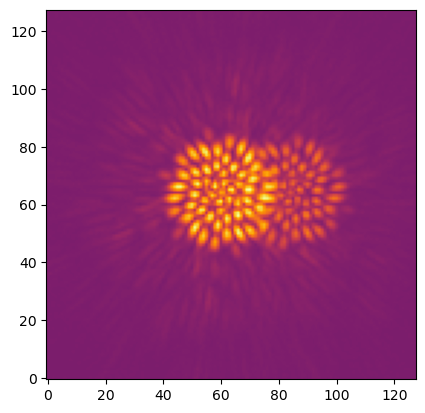

In [11]:
plt.figure()
plt.imshow(data.centre_reference,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0));

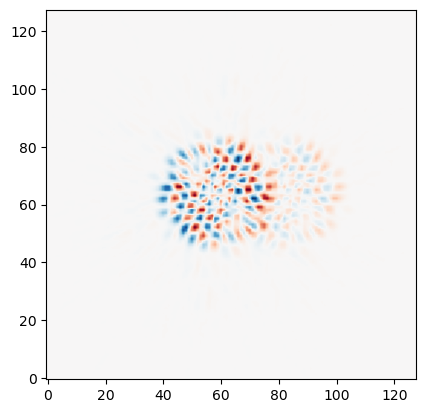

In [12]:
plt.figure()
plt.imshow(data.centre_differences[0],origin='lower',cmap='RdBu');

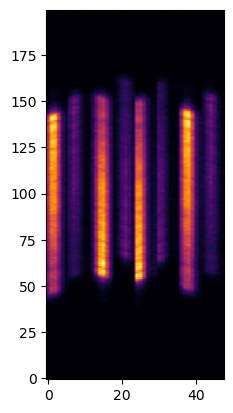

In [13]:
plt.figure()
plt.imshow(data.sidelobe_reference,origin='lower',cmap='inferno', aspect=0.5);

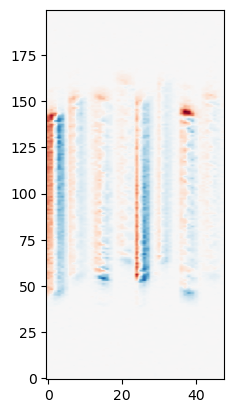

In [14]:
plt.figure()
img = data.sidelobe_differences[0]
max_value = np.max([np.max(img),np.abs(np.min(img))])
plt.imshow(img,origin='lower',cmap='RdBu', aspect=0.5, vmin=-max_value, vmax=max_value);

## Debugging compression pipeline

In [19]:
params = compress_params

In [35]:
from workers.compression import *
from workers.compression import _meta_path, _load_metadata, _load_frame_stack, _corner_roi_shape, _centre_roi_shape, _get_corner_offsets

In [27]:
kernel = load_deconvolution_kernel(params.kernel_path)

In [28]:
meta_path = _meta_path(system.data_dir, params.session_id,
                           params.centre_roi_label)
metadata = _load_metadata(meta_path)

In [30]:
n_frames_total = len(metadata)

In [33]:
centre_stack = _load_frame_stack(
    system.data_dir,
    params.session_id,
    params.centre_roi_label,
    _centre_roi_shape(system,session),
    n_frames_total,
)

In [34]:
corner_stacks: Dict[str, np.ndarray] = {}
for label in params.corner_roi_labels:
    shape = _corner_roi_shape(system, session, label)
    if shape is None:
        logger.warning("No shape found for corner ROI '%s' - skipping.", label)
        continue
    corner_stacks[label] = _load_frame_stack(
        system.data_dir, params.session_id,
        label, shape, n_frames_total,
    )

In [36]:
centre_offset_x, centre_offset_y = system.centre_roi_offset(session)
corner_offsets = _get_corner_offsets(system, session)

In [37]:
n_batches = (n_frames_total + params.batch_size_n - 1) // params.batch_size_n

In [38]:
batch_idx = 0

In [39]:
start = batch_idx * params.batch_size_n
end   = min(start + params.batch_size_n, n_frames_total)

batch_meta   = metadata[start:end]
batch_centre = centre_stack[start:end]
batch_corners = {
    label: stack[start:end]
    for label, stack in corner_stacks.items()
}

In [40]:
sidelobe_strips: List[Optional[np.ndarray]] = []

In [63]:
frame_idx = 1

In [64]:
centre_frame = batch_centre[frame_idx]
stars_local = find_stars(centre_frame, kernel, n_stars=params.n_stars)
print(stars_local)

{'xs': [57.0, 81.0], 'ys': [64.0, 64.0]}


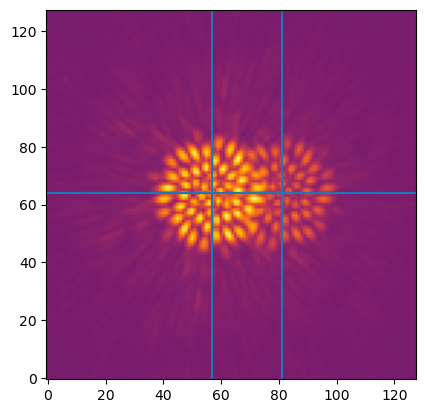

In [65]:
plt.figure()
plt.imshow(centre_frame,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0))
for x in stars_local['xs']:
    plt.axvline(x)
for y in stars_local['ys']:
    plt.axhline(y)
plt.show()

In [66]:
stars_sensor = roi_local_to_sensor(
            stars_local["xs"], stars_local["ys"],
            centre_offset_x, centre_offset_y,
        )

In [67]:
stars_sensor

{'xs': [2249.0, 2273.0], 'ys': [2256.0, 2256.0]}

In [68]:
star_positions_per_corner = {
            label: sensor_to_roi_local(
                stars_sensor["xs"], stars_sensor["ys"],
                *corner_offsets.get(label, (0, 0)),
            )
            for label in batch_corners
        }

In [69]:
star_positions_per_corner

{'top_right': {'xs': [-2017.0, -1993.0], 'ys': [2256.0, 2256.0]},
 'bot_right': {'xs': [-2017.0, -1993.0], 'ys': [-2010.0, -2010.0]},
 'bot_left': {'xs': [2249.0, 2273.0], 'ys': [-2010.0, -2010.0]},
 'top_left': {'xs': [2249.0, 2273.0], 'ys': [2256.0, 2256.0]}}

In [70]:
corner_frames = {
            label: stack[frame_idx]
            for label, stack in batch_corners.items()
        }

In [71]:
merged = crop_and_merge_corners(
            corner_frames,
            star_positions_per_corner,
            corner_angles=params.corner_angles,
            width=params.strip_width,
        )

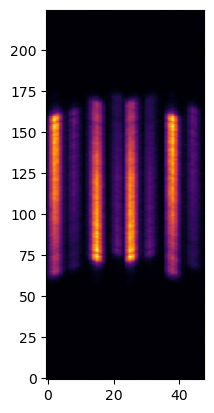

In [72]:
plt.figure()
plt.imshow(merged,origin='lower',cmap='inferno', aspect=0.5);

In [74]:
n = len(batch_meta)

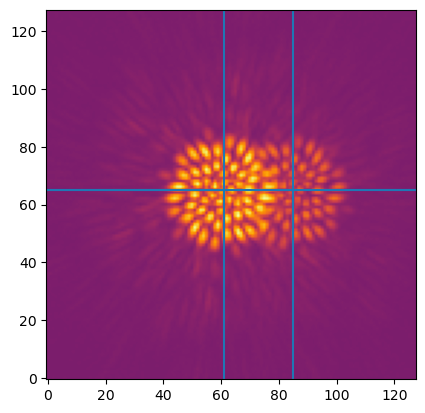

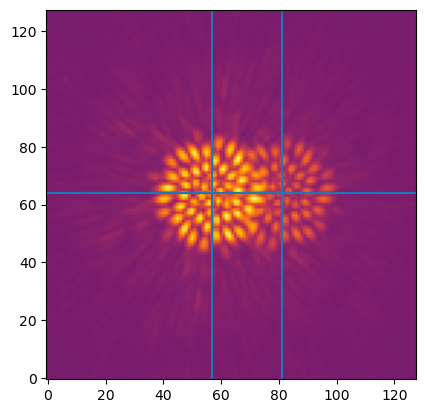

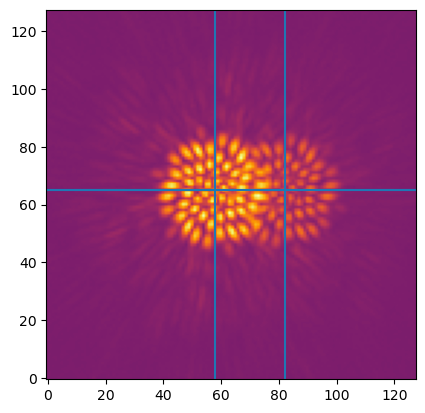

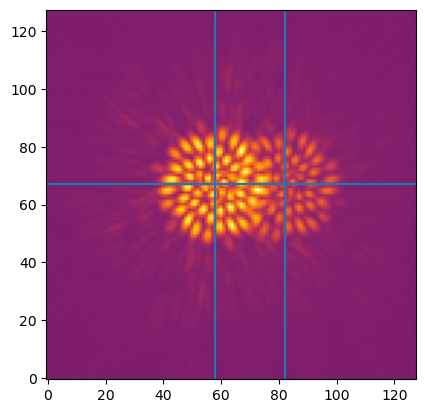

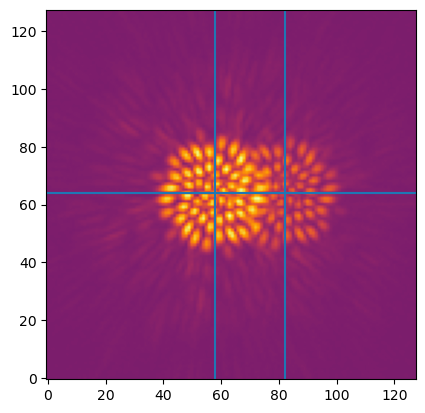

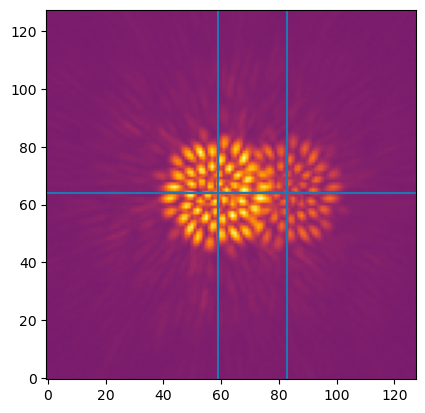

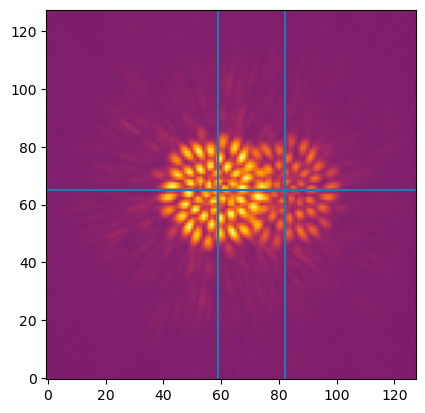

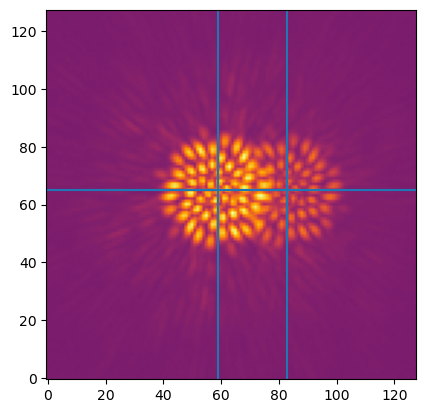

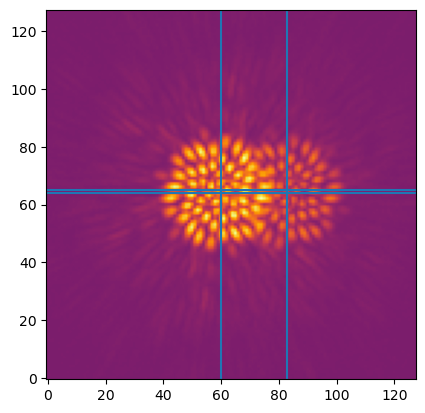

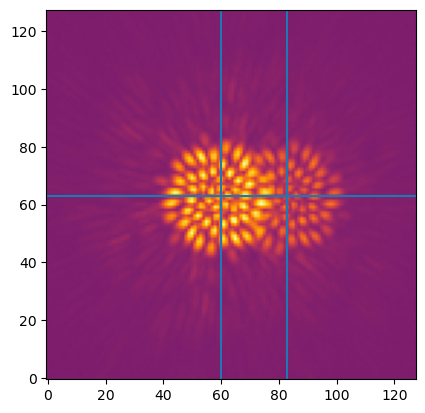

In [75]:
sidelobe_strips: List[Optional[np.ndarray]] = []

for frame_idx in range(n):
    centre_frame = batch_centre[frame_idx]

    # Find stars in centre ROI (ROI-local coordinates)
    stars_local = find_stars(
        centre_frame, kernel,
        n_stars=params.n_stars,
    )

    plt.figure()
    plt.imshow(centre_frame,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0))
    for x in stars_local['xs']:
        plt.axvline(x)
    for y in stars_local['ys']:
        plt.axhline(y)
    plt.show()
    
    # Convert to sensor coordinates
    stars_sensor = roi_local_to_sensor(
        stars_local["xs"], stars_local["ys"],
        centre_offset_x, centre_offset_y,
    )

    # Transform star positions into each corner ROI's local coordinates
    # and extract + merge all sidelobe strips for this frame.
    star_positions_per_corner = {
        label: sensor_to_roi_local(
            stars_sensor["xs"], stars_sensor["ys"],
            *corner_offsets.get(label, (0, 0)),
        )
        for label in batch_corners
    }

    corner_frames = {
        label: stack[frame_idx]
        for label, stack in batch_corners.items()
    }

    merged = crop_and_merge_corners(
        corner_frames,
        star_positions_per_corner,
        corner_angles=params.corner_angles,
        width=params.strip_width,
    )

    sidelobe_strips.append(merged)
    if merged is None:
        logger.warning(
            "Batch %d frame %d: no sidelobe strips extracted.",
            batch_idx, frame_idx,
        )

(220, 48)
(225, 48)
(223, 48)
(221, 48)
(224, 48)
(223, 48)
(223, 48)
(222, 48)
(223, 48)
(223, 48)


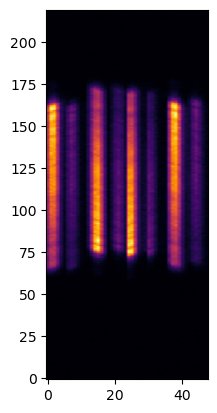

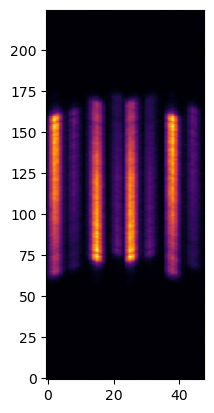

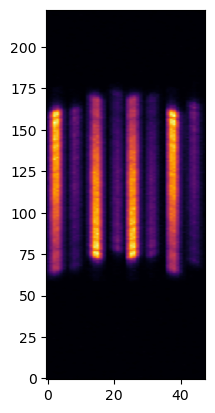

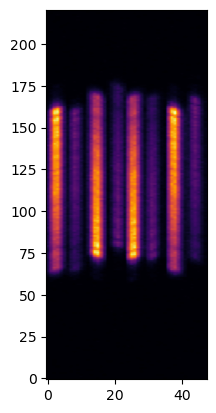

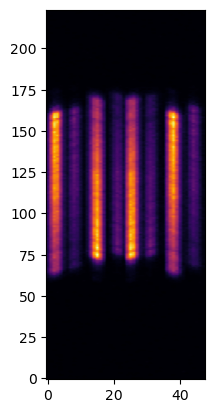

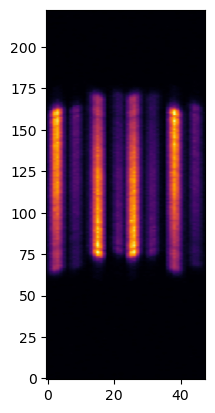

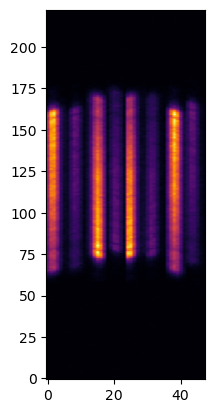

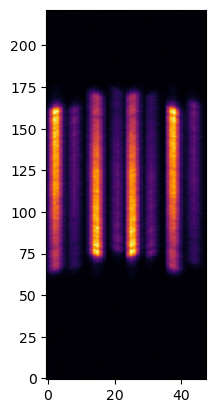

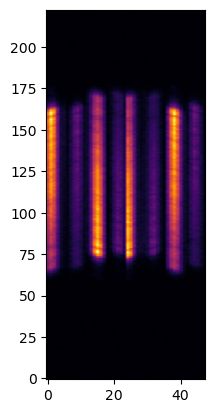

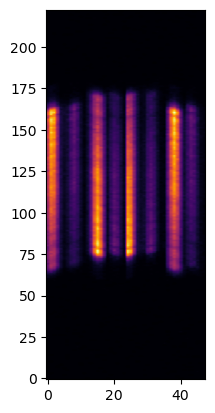

In [86]:
for img in sidelobe_strips:
    print(img.shape)
    plt.figure()
    plt.imshow(img,origin='lower',cmap='inferno', aspect=0.5);

In [87]:
params

CompressionParams(session_id='sim_run_0002', batch_size_n=10, n_stars=2, kernel_path='deconvolution_constant.npy', sidelobe_offset=1625, strip_width=6, corner_roi_labels=['top_right', 'bot_right', 'bot_left', 'top_left'], centre_roi_label='centre', corner_angles={'top_left': 45.0, 'top_right': 135.0, 'bot_left': 135.0, 'bot_right': 45.0})

In [79]:
valid_strips = [s for s in sidelobe_strips if s is not None]

In [81]:
len(valid_strips)

10

In [82]:
strip_shape = valid_strips[0].shape

In [83]:
sl_stack = np.zeros((n, *strip_shape), dtype=np.uint16)

In [84]:
strip_shape

(220, 48)

In [85]:
sl_stack.shape

(10, 220, 48)

In [ ]:
for i, strip in enumerate(sidelobe_strips):
    if strip is not None and strip.shape == strip_shape:
            sl_stack[i] = strip